# Stage 12C — Training-Only Neighbour Reference and Paired Evaluation

**Final controlled experiment.** This notebook builds on the verified Stage 12B execution with two targeted changes:

1. Adversarial graph neighbours are selected from **clean training nodes only** (not validation or test nodes).
2. In addition to the full clean-test versus successful-adversarial evaluation, it performs a **paired 793-versus-793 comparison** using each successful adversarial sample and its exact original clean counterpart.

Clean Stage 6 embeddings remain frozen. A single 95th-percentile threshold per score is calibrated using clean validation embeddings and shared across attacks.

**Important limitation:** Stage 6 DGI was trained transductively on the full clean graph. Stage 12C restricts inference-time adversarial neighbours to training nodes; it does not undo transductive exposure during Stage 6 training.

Run all cells sequentially. Do not bypass assertions.


In [1]:
# 0. Environment and reproducibility
import os, json, zipfile, random, shutil, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.neighbors import NearestNeighbors
from sklearn.covariance import LedoitWolf
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", DEVICE)


PyTorch: 2.14.1+cpu | Device: cpu


In [2]:
# 1. Mount Google Drive and locate the required inputs
from google.colab import drive
drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/Alzheimer_DGI_Research')
INPUT = ROOT / 'Stage12_Inputs'
WORK = Path('/content/stage12_corrected_work')
OUT = ROOT / 'Stage12_Corrected_Outputs'
WORK.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

# Core ZIP dependencies
required_zips = ['Stage4_CNN_Outputs.zip', 'Stage5_Graph_Outputs.zip', 'Stage6_DGI_Outputs.zip']
missing_zips = [f for f in required_zips if not (INPUT / f).is_file()]
if missing_zips:
    raise FileNotFoundError(f"Missing required ZIP archives in {INPUT}:\n- " + '\n- '.join(missing_zips))

# Map of expected keys to actual files present on Google Drive
attack_prefixes = [
    'validation_FGSM', 'validation_PGD', 'validation_CW_L2',
    'test_FGSM', 'test_PGD', 'test_CW_L2'
]

# Auto-resolve names: prefer '_correct_only.npz', fall back to '_adversarial.npz'
resolved_attacks = {}
missing_attacks = []

for prefix in attack_prefixes:
    opt1 = INPUT / f"{prefix}_correct_only.npz"
    opt2 = INPUT / f"{prefix}_adversarial.npz"
    if opt1.is_file():
        resolved_attacks[prefix] = opt1
    elif opt2.is_file():
        resolved_attacks[prefix] = opt2
    else:
        missing_attacks.append(f"{prefix}_correct_only.npz (or _adversarial.npz)")

if missing_attacks:
    raise FileNotFoundError(
        'Missing required attack files in ' + str(INPUT) + ':\n- ' + '\n- '.join(missing_attacks) +
        '\nPlease upload/copy these files into Stage12_Inputs.'
    )

print('All required inputs found and resolved:')
for f in required_zips:
    print(' •', f, (INPUT/f).stat().st_size, 'bytes')
for k, path in resolved_attacks.items():
    print(' •', path.name, path.stat().st_size, 'bytes')

# Patch the notebook-wide lookup to use the resolved file paths dynamically
def load_attack_patched(split, attack):
    prefix = f"{split}_{attack}"
    path = resolved_attacks[prefix]
    with np.load(path, allow_pickle=False) as z: rec = {k:z[k] for k in z.files}
    required_keys = ['indices','original_images','adversarial_images','labels','clean_predictions',
                    'adversarial_predictions','attack_success']
    missing_keys = [k for k in required_keys if k not in rec]
    if missing_keys: raise KeyError(f'{path.name} missing keys: {missing_keys}')
    ids = rec['indices'].astype(np.int64)
    n = len(ids)
    assert n > 0 and len(np.unique(ids)) == n
    assert np.isin(ids,SPLITS[split]).all(), f'{path.name}: indices outside {split} split'
    assert rec['original_images'].shape == (n,1,128,128)
    assert rec['adversarial_images'].shape == (n,1,128,128)
    assert rec['labels'].shape == (n,) and rec['clean_predictions'].shape == (n,)
    assert rec['adversarial_predictions'].shape == (n,) and rec['attack_success'].shape == (n,)
    for key in ['original_images','adversarial_images']:
        arr = rec[key]
        assert np.isfinite(arr).all() and arr.min() >= -1e-6 and arr.max() <= 1+1e-6
    assert np.array_equal(rec['clean_predictions'],rec['labels']), f'{path.name}: input not clean-correct'
    assert np.array_equal(rec['attack_success'].astype(bool),rec['adversarial_predictions'] != rec['labels'])
    assert np.array_equal(rec['labels'],np.array([clean_label_by_idx[int(i)] for i in ids]))
    assert np.array_equal(rec['clean_predictions'],np.array([clean_pred_by_idx[int(i)] for i in ids]))
    return rec

# Injecting our resolver helper into global scope for step 5
globals()['load_attack'] = load_attack_patched

Mounted at /content/drive
All required inputs found and resolved:
 • Stage4_CNN_Outputs.zip 4613638 bytes
 • Stage5_Graph_Outputs.zip 2114913 bytes
 • Stage6_DGI_Outputs.zip 3242740 bytes
 • validation_FGSM_adversarial.npz 30001211 bytes
 • validation_PGD_adversarial.npz 41575369 bytes
 • validation_CW_L2_adversarial.npz 44315438 bytes
 • test_FGSM_adversarial.npz 30010576 bytes
 • test_PGD_adversarial.npz 41582650 bytes
 • test_CW_L2_adversarial.npz 44150264 bytes


In [3]:
import os
from pathlib import Path

input_dir = Path('/content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Inputs')

if input_dir.exists():
    print(f"Checking contents of: {input_dir}\n")
    files = sorted(os.listdir(input_dir))
    if not files:
        print("The directory is empty.")
    for f in files:
        file_path = input_dir / f
        size_mb = file_path.stat().st_size / (1024 * 1024) if file_path.is_file() else 0
        print(f"• {f:<40} | {'File' if file_path.is_file() else 'Folder'} | {size_mb:.2f} MB")
else:
    print(f"Directory not found: {input_dir}\nPlease ensure Google Drive is mounted and the path is correct.")

Checking contents of: /content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Inputs

• Stage4_CNN_Outputs.zip                   | File | 4.40 MB
• Stage5_Graph_Outputs.zip                 | File | 2.02 MB
• Stage6_DGI_Outputs.zip                   | File | 3.09 MB
• test_CW_L2_adversarial.npz               | File | 42.10 MB
• test_FGSM_adversarial.npz                | File | 28.62 MB
• test_PGD_adversarial.npz                 | File | 39.66 MB
• validation_CW_L2_adversarial.npz         | File | 42.26 MB
• validation_FGSM_adversarial.npz          | File | 28.61 MB
• validation_PGD_adversarial.npz           | File | 39.65 MB


In [4]:
# Execute extraction of Stage 4, 5, and 6 ZIP archives
import zipfile
import shutil
from pathlib import Path

def safe_extract(zip_path, dest):
    dest = Path(dest)
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zf:
        for member in zf.infolist():
            target = (dest / member.filename).resolve()
            # Prevent directory traversal attacks
            if not str(target).startswith(str(dest.resolve()) + '/'):
                if target != dest.resolve():
                    raise ValueError(f'Unsafe ZIP member path: {member.filename}')
        zf.extractall(dest)

# Configure paths
INPUT_DIR = Path('/content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Inputs')
WORK_DIR = Path('/content/stage12_corrected_work')

DIRS = {}
for key in ['Stage4', 'Stage5', 'Stage6']:
    dest = WORK_DIR / key.lower()
    if dest.exists():
        shutil.rmtree(dest)

    zip_name = {
        'Stage4': 'Stage4_CNN_Outputs.zip',
        'Stage5': 'Stage5_Graph_Outputs.zip',
        'Stage6': 'Stage6_DGI_Outputs.zip'
    }[key]

    zip_path = INPUT_DIR / zip_name
    safe_extract(zip_path, dest)
    DIRS[key] = dest
    print(f"Extracted {key} to {dest}")

Extracted Stage4 to /content/stage12_corrected_work/stage4
Extracted Stage5 to /content/stage12_corrected_work/stage5
Extracted Stage6 to /content/stage12_corrected_work/stage6


In [5]:
# 2. Safely extract Stage 4, Stage 5 and Stage 6 archives

def safe_extract(zip_path, dest):
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zf:
        for member in zf.infolist():
            target = (dest / member.filename).resolve()
            if not str(target).startswith(str(dest.resolve()) + os.sep) and target != dest.resolve():
                raise ValueError(f'Unsafe ZIP member path: {member.filename}')
        zf.extractall(dest)

DIRS = {}
for key in ['Stage4','Stage5','Stage6']:
    dest = WORK / key.lower()
    if dest.exists(): shutil.rmtree(dest)
    safe_extract(INPUT / f'{key}_' + 'CNN_Outputs.zip' if False else INPUT / ({'Stage4':'Stage4_CNN_Outputs.zip','Stage5':'Stage5_Graph_Outputs.zip','Stage6':'Stage6_DGI_Outputs.zip'}[key]), dest)
    DIRS[key] = dest
    print(key, 'files:', [p.name for p in dest.rglob('*') if p.is_file()])

def find_exact(root, filename):
    found = list(Path(root).rglob(filename))
    if len(found) != 1:
        raise FileNotFoundError(f'Expected exactly one {filename} under {root}; found {len(found)}')
    return found[0]


Stage4 files: ['stage4_config_and_metrics.json', 'cnn_embedding_manifest.csv', 'cnn_training_history.csv', 'cnn_test_class_metrics.csv', 'best_alzheimer_cnn.pth', 'cnn_embeddings_128d.npz', 'cnn_test_confusion_matrix.csv']
Stage5 files: ['graph_node_features_and_masks.npz', 'cosine_knn_adjacency.npz', 'graph_node_manifest.csv', 'cosine_knn_edges_directed.csv', 'graph_construction_config.json']
Stage6 files: ['stage6_dgi_gcn_model.pt', 'stage6_dgi_graph_embeddings.npz', 'stage6_dgi_config.json', 'stage6_dgi_training_history.csv']


## 3. Reconstruct and verify the clean CNN feature matrix

In [6]:
from pathlib import Path
import numpy as np

# Ensure WORK, DIRS, and find_exact are defined if preceding cells weren't run
if 'WORK' not in globals():
    WORK = Path('/content/stage12_corrected_work')
if 'DIRS' not in globals():
    DIRS = {
        'Stage4': WORK / 'stage4',
        'Stage5': WORK / 'stage5',
        'Stage6': WORK / 'stage6'
    }

def find_exact(root, filename):
    found = list(Path(root).rglob(filename))
    if len(found) != 1:
        raise FileNotFoundError(f'Expected exactly one {filename} under {root}; found {len(found)}')
    return found[0]

emb_path = find_exact(DIRS['Stage4'], 'cnn_embeddings_128d.npz')
cnn_ckpt_path = find_exact(DIRS['Stage4'], 'best_alzheimer_cnn.pth')
with np.load(emb_path, allow_pickle=False) as z:
    emb = {k: z[k] for k in z.files}

needed = ['train_embeddings','validation_embeddings','test_embeddings',
          'train_indices','validation_indices','test_indices',
          'train_labels','validation_labels','test_labels',
          'train_predictions','validation_predictions','test_predictions']
missing = [k for k in needed if k not in emb]
if missing: raise KeyError(f'Stage 4 embeddings archive missing: {missing}')
idx_train = emb['train_indices'].astype(np.int64)
idx_val = emb['validation_indices'].astype(np.int64)
idx_test = emb['test_indices'].astype(np.int64)
N = len(idx_train) + len(idx_val) + len(idx_test)
assert N == 6400, f'Expected 6400 nodes, found {N}'
assert len(np.unique(np.concatenate([idx_train,idx_val,idx_test]))) == N
X_clean = np.zeros((N,128), dtype=np.float32)
X_clean[idx_train] = emb['train_embeddings'].astype(np.float32)
X_clean[idx_val] = emb['validation_embeddings'].astype(np.float32)
X_clean[idx_test] = emb['test_embeddings'].astype(np.float32)
assert np.isfinite(X_clean).all()

# Verify Stage 4 embeddings exactly match the feature matrix used to construct Stage 5.
node_npz = find_exact(DIRS['Stage5'], 'graph_node_features_and_masks.npz')
with np.load(node_npz, allow_pickle=False) as z:
    node_data = {k:z[k] for k in z.files}
assert node_data['node_features'].shape == (N,128)
max_feature_diff = float(np.max(np.abs(X_clean - node_data['node_features'])))
print('Stage4-to-Stage5 max absolute feature difference:', max_feature_diff)
assert max_feature_diff < 1e-6, 'Stage 4 features do not match Stage 5 node features; stop.'

# Split masks must agree with Stage 5 output.
assert np.array_equal(node_data['train_mask'], np.isin(np.arange(N), idx_train))
assert np.array_equal(node_data['validation_mask'], np.isin(np.arange(N), idx_val))
assert np.array_equal(node_data['test_mask'], np.isin(np.arange(N), idx_test))
print('Clean features verified:', X_clean.shape, '| split counts:',len(idx_train),len(idx_val),len(idx_test))

Stage4-to-Stage5 max absolute feature difference: 0.0
Clean features verified: (6400, 128) | split counts: 4480 960 960


In [ ]:
import os
from pathlib import Path

stage4_path = Path('/content/stage12_corrected_work/stage4')
if stage4_path.exists():
    print(f"Contents of {stage4_path}:")
    for item in sorted(stage4_path.rglob('*')):
        if item.is_file():
            size_mb = item.stat().st_size / (1024 * 1024)
            print(f"  • {item.relative_to(stage4_path)} ({size_mb:.4f} MB)")
else:
    print(f"Directory does not exist: {stage4_path}")

Directory does not exist: /content/stage12_corrected_work/stage4


## 4. Load the exact Stage 4 CNN and verify the Stage 6 DGI-GCN checkpoint

In [7]:
from pathlib import Path
import numpy as np
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F

# Ensure WORK, DIRS, paths, and indices are defined if preceding cells weren't run
if 'WORK' not in globals():
    WORK = Path('/content/stage12_corrected_work')
if 'DIRS' not in globals():
    DIRS = {
        'Stage4': WORK / 'stage4',
        'Stage5': WORK / 'stage5',
        'Stage6': WORK / 'stage6'
    }

def find_exact(root, filename):
    found = list(Path(root).rglob(filename))
    if len(found) != 1:
        raise FileNotFoundError(f'Expected exactly one {filename} under {root}; found {len(found)}')
    return found[0]

# Safely resolve necessary variables if they are missing from global scope
if 'cnn_ckpt_path' not in globals():
    cnn_ckpt_path = find_exact(DIRS['Stage4'], 'best_alzheimer_cnn.pth')
if 'X_clean' not in globals() or 'idx_train' not in globals():
    emb_path = find_exact(DIRS['Stage4'], 'cnn_embeddings_128d.npz')
    with np.load(emb_path, allow_pickle=False) as z:
        emb = {k: z[k] for k in z.files}
    idx_train = emb['train_indices'].astype(np.int64)
    idx_val = emb['validation_indices'].astype(np.int64)
    idx_test = emb['test_indices'].astype(np.int64)
    N = len(idx_train) + len(idx_val) + len(idx_test)
    X_clean = np.zeros((N, 128), dtype=np.float32)
    X_clean[idx_train] = emb['train_embeddings'].astype(np.float32)
    X_clean[idx_val] = emb['validation_embeddings'].astype(np.float32)
    X_clean[idx_test] = emb['test_embeddings'].astype(np.float32)

class AlzheimerCNN(nn.Module):
    def __init__(self, num_classes=4, embedding_dim=128, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1,32,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128,256,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.global_pool = nn.AdaptiveAvgPool2d((1,1))
        self.embedding = nn.Linear(256, embedding_dim)
        self.embedding_activation = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)
    def forward(self, x, return_embedding=False):
        x = self.features(x); x = self.global_pool(x); x = torch.flatten(x,1)
        z = self.embedding_activation(self.embedding(x))
        logits = self.classifier(self.dropout(z))
        return (logits,z) if return_embedding else logits

cnn_ckpt = torch.load(cnn_ckpt_path, map_location=DEVICE, weights_only=False)
class_names = cnn_ckpt.get('class_names', ['Mild Demented','Moderate Demented','Non-Demented','Very Mild Demented'])
cnn = AlzheimerCNN(num_classes=len(class_names)).to(DEVICE)
cnn.load_state_dict(cnn_ckpt['model_state_dict'], strict=True)
cnn.eval()
print('Stage 4 CNN checkpoint loaded; best epoch:', cnn_ckpt.get('epoch'))

# Stage 5 adjacency and its original symmetric-normalisation procedure.
A_path = find_exact(DIRS['Stage5'], 'cosine_knn_adjacency.npz')
A = sp.load_npz(A_path).tocsr().astype(np.float32)
assert A.shape == (N,N) and (A-A.T).nnz == 0
assert A.diagonal().sum() == 0 and np.isfinite(A.data).all() and np.all(A.data >= 0)
print('Stage 5 adjacency verified:', A.shape, '| undirected edges:', A.nnz//2)

# Stage 6 model architecture copied from the executed Stage 6 notebook.
class GraphConvolution(nn.Module):
    def __init__(self, in_features, out_features, bias=True):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(in_features,out_features))
        nn.init.xavier_uniform_(self.weight)
        self.bias = nn.Parameter(torch.zeros(out_features)) if bias else None
    def forward(self, x, adj):
        support = torch.matmul(x,self.weight)
        out = torch.sparse.mm(adj,support)
        if self.bias is not None: out = out + self.bias
        return out

class GCNEncoder(nn.Module):
    def __init__(self, in_dim=128, hidden_dim=128, dropout=0.5):
        super().__init__()
        self.gc1 = GraphConvolution(in_dim,hidden_dim)
        self.gc2 = GraphConvolution(hidden_dim,hidden_dim)
        self.dropout = dropout
    def forward(self,x,adj):
        h = self.gc1(x,adj); h = F.relu(h)
        h = F.dropout(h,p=self.dropout,training=self.training)
        return self.gc2(h,adj)

def scipy_to_torch_sparse(matrix, device):
    coo = matrix.tocoo()
    indices = torch.tensor(np.vstack([coo.row,coo.col]),dtype=torch.long,device=device)
    values = torch.tensor(coo.data,dtype=torch.float32,device=device)
    return torch.sparse_coo_tensor(indices,values,coo.shape,device=device).coalesce()

def normalize_adjacency(adj):
    ahat = (adj + sp.eye(adj.shape[0],dtype=np.float32,format='csr')).tocsr()
    degree = np.asarray(ahat.sum(axis=1)).ravel().astype(np.float32)
    inv = np.power(degree,-0.5); inv[np.isinf(inv)] = 0.0
    return (sp.diags(inv) @ ahat @ sp.diags(inv)).tocsr().astype(np.float32)

A_norm = normalize_adjacency(A)
A_torch = scipy_to_torch_sparse(A_norm,DEVICE)
X_torch = torch.tensor(X_clean,dtype=torch.float32,device=DEVICE)
gcn = GCNEncoder().to(DEVICE)
dgi_ckpt_path = find_exact(DIRS['Stage6'],'stage6_dgi_gcn_model.pt')
dgi_state = torch.load(dgi_ckpt_path,map_location=DEVICE,weights_only=True)
encoder_state = {k.replace('encoder.','',1):v for k,v in dgi_state.items() if k.startswith('encoder.')}
if not encoder_state: raise KeyError('No encoder.* parameters found in Stage 6 checkpoint')
gcn.load_state_dict(encoder_state,strict=True)
gcn.eval()

stage6_npz = find_exact(DIRS['Stage6'],'stage6_dgi_graph_embeddings.npz')
with np.load(stage6_npz,allow_pickle=False) as z:
    H_stage6 = z['graph_embeddings'].astype(np.float32)
    s6_train = z['train_indices'].astype(np.int64)
    s6_val = z['val_indices'].astype(np.int64)
    s6_test = z['test_indices'].astype(np.int64)
assert np.array_equal(idx_train,s6_train) and np.array_equal(idx_val,s6_val) and np.array_equal(idx_test,s6_test)
with torch.no_grad(): H_recomputed = gcn(X_torch,A_torch).cpu().numpy().astype(np.float32)
max_dgi_diff = float(np.max(np.abs(H_recomputed-H_stage6)))
print('Stage6 embedding reconstruction max abs difference:',max_dgi_diff)
assert max_dgi_diff < 1e-4, 'Stage 6 checkpoint does not reproduce saved embeddings; stop.'

Stage 4 CNN checkpoint loaded; best epoch: 49
Stage 5 adjacency verified: (6400, 6400) | undirected edges: 43681
Stage6 embedding reconstruction max abs difference: 0.0


/tmp/ipykernel_1070/2955978449.py:101: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices,values,coo.shape,device=device).coalesce()


## 5. Load and rigorously validate the real Stage 7 validation/test attack files

In [8]:
ATTACKS = ['FGSM','PGD','CW_L2']
SPLITS = {'validation':idx_val,'test':idx_test}

# Map Stage 4 clean labels/predictions by original image index.
clean_label_by_idx = {}
clean_pred_by_idx = {}
for split in ['train','validation','test']:
    ids = emb[f'{split}_indices'].astype(np.int64)
    labs = emb[f'{split}_labels'].astype(np.int64)
    preds = emb[f'{split}_predictions'].astype(np.int64)
    clean_label_by_idx.update(dict(zip(ids.tolist(),labs.tolist())))
    clean_pred_by_idx.update(dict(zip(ids.tolist(),preds.tolist())))

def load_attack(split,attack):
    # Re-use our dynamic resolver dictionary from cell 895ce48e if available, otherwise fallback
    prefix = f"{split}_{attack}"
    if 'resolved_attacks' in globals() and prefix in globals()['resolved_attacks']:
        path = globals()['resolved_attacks'][prefix]
    else:
        opt1 = INPUT / f'{split}_{attack}_correct_only.npz'
        opt2 = INPUT / f'{split}_{attack}_adversarial.npz'
        path = opt1 if opt1.is_file() else opt2

    with np.load(path,allow_pickle=False) as z: rec = {k:z[k] for k in z.files}
    required = ['indices','original_images','adversarial_images','labels','clean_predictions',
                'adversarial_predictions','attack_success']
    missing = [k for k in required if k not in rec]
    if missing: raise KeyError(f'{path.name} missing keys: {missing}')

    # If the file is a full '_adversarial.npz' file instead of '_correct_only.npz',
    # filter down to only include clean-correctly predicted items
    clean_correct_mask = (rec['clean_predictions'] == rec['labels'])
    if not clean_correct_mask.all():
        print(f"[Info] Filtering {path.name}: retaining {clean_correct_mask.sum()} clean-correct samples out of {len(clean_correct_mask)} total.")
        for k in rec.keys():
            rec[k] = rec[k][clean_correct_mask]

    ids = rec['indices'].astype(np.int64)
    n = len(ids)
    assert n > 0 and len(np.unique(ids)) == n
    assert np.isin(ids,SPLITS[split]).all(), f'{path.name}: indices outside {split} split'
    assert rec['original_images'].shape == (n,1,128,128)
    assert rec['adversarial_images'].shape == (n,1,128,128)
    assert rec['labels'].shape == (n,) and rec['clean_predictions'].shape == (n,)
    assert rec['adversarial_predictions'].shape == (n,) and rec['attack_success'].shape == (n,)
    for key in ['original_images','adversarial_images']:
        arr = rec[key]
        assert np.isfinite(arr).all() and arr.min() >= -1e-6 and arr.max() <= 1+1e-6
    assert np.array_equal(rec['clean_predictions'],rec['labels']), f'{path.name}: input not clean-correct'
    assert np.array_equal(rec['attack_success'].astype(bool),rec['adversarial_predictions'] != rec['labels'])
    assert np.array_equal(rec['labels'],np.array([clean_label_by_idx[int(i)] for i in ids]))
    assert np.array_equal(rec['clean_predictions'],np.array([clean_pred_by_idx[int(i)] for i in ids]))
    return rec

attack_data = {}
for split in ['validation','test']:
    for attack in ATTACKS:
        rec = load_attack(split,attack)
        attack_data[(split,attack)] = rec
        print(split,attack,'eligible:',len(rec['indices']),'successful:',int(rec['attack_success'].sum()),
              'failed:',int((~rec['attack_success'].astype(bool)).sum()))

# Confirm test attack index sets are identical across attacks and reproduce the audited 793 samples.
test_index_sets = [set(attack_data[('test',a)]['indices'].tolist()) for a in ATTACKS]
assert test_index_sets[0] == test_index_sets[1] == test_index_sets[2]
assert len(test_index_sets[0]) == 793, f'Expected the previously audited 793 clean-correct test indices; found {len(test_index_sets[0])}'
for a in ATTACKS:
    r = attack_data[('test',a)]
    assert int(r['attack_success'].sum()) == 793 and len(r['indices']) == 793
print('Stage 7 test files verified: same 793 clean-correct test indices across all attacks.')

# The same clean-correct samples must be attacked in all three attack runs within each split.
for split in ['validation','test']:
    base = attack_data[(split,'FGSM')]
    for attack in ['PGD','CW_L2']:
        other = attack_data[(split,attack)]
        assert np.array_equal(base['indices'],other['indices']), f'{split}: index mismatch between FGSM and {attack}'
        assert np.array_equal(base['labels'],other['labels']), f'{split}: label mismatch between FGSM and {attack}'
        assert np.allclose(base['original_images'],other['original_images'],atol=1e-7), f'{split}: original image mismatch between attacks'
print('Cross-attack original-image, label and index alignment verified for validation and test.')

[Info] Filtering validation_FGSM_adversarial.npz: retaining 798 clean-correct samples out of 960 total.
validation FGSM eligible: 798 successful: 797 failed: 1
[Info] Filtering validation_PGD_adversarial.npz: retaining 798 clean-correct samples out of 960 total.
validation PGD eligible: 798 successful: 798 failed: 0
[Info] Filtering validation_CW_L2_adversarial.npz: retaining 798 clean-correct samples out of 960 total.
validation CW_L2 eligible: 798 successful: 798 failed: 0
[Info] Filtering test_FGSM_adversarial.npz: retaining 793 clean-correct samples out of 960 total.
test FGSM eligible: 793 successful: 793 failed: 0
[Info] Filtering test_PGD_adversarial.npz: retaining 793 clean-correct samples out of 960 total.
test PGD eligible: 793 successful: 793 failed: 0
[Info] Filtering test_CW_L2_adversarial.npz: retaining 793 clean-correct samples out of 960 total.
test CW_L2 eligible: 793 successful: 793 failed: 0
Stage 7 test files verified: same 793 clean-correct test indices across all 

## 6. Stage 12C: frozen clean embeddings and training-only adversarial neighbours

Clean embeddings are calculated on the original Stage 5 graph and frozen. Each adversarial node connects only to its 10 nearest **training** nodes in the Stage 4 CNN feature space. No validation or test clean image is eligible to be a graph neighbour, and no edge flows from a clean node to an adversarial node.


In [11]:
# Stage 12C: immutable clean embeddings and train-only one-way inference

# Load missing masks from Stage 5 metadata and construct node_ids
node_npz = find_exact(DIRS['Stage5'], 'graph_node_features_and_masks.npz')
with np.load(node_npz, allow_pickle=False) as z:
    val_mask = z['validation_mask']
    test_mask = z['test_mask']

node_ids = np.arange(N, dtype=np.int64)

K_NEIGHBORS = 10
H_CLEAN = H_recomputed.astype(np.float32)
assert H_CLEAN.shape == (N,128)
H_TRAIN, H_VAL, H_TEST = H_CLEAN[idx_train], H_CLEAN[idx_val], H_CLEAN[idx_test]

# Map original dataset image index -> row in the global Stage 4/5 node arrays.
global_row_by_index = {int(original_id): row for row, original_id in enumerate(node_ids)}
train_global_rows = np.asarray([global_row_by_index[int(i)] for i in idx_train],dtype=np.int64)
assert len(train_global_rows)==len(idx_train)
assert set(train_global_rows).isdisjoint(set(np.where(val_mask)[0]))
assert set(train_global_rows).isdisjoint(set(np.where(test_mask)[0]))

# Neighbour search is fitted ONLY on clean training CNN features.
X_train = X_clean[train_global_rows]
X_train_unit = X_train / np.maximum(np.linalg.norm(X_train,axis=1,keepdims=True),1e-12)
train_feature_knn = NearestNeighbors(
    n_neighbors=K_NEIGHBORS,metric='cosine',algorithm='brute',n_jobs=-1
).fit(X_train_unit)

def extract_cnn_embeddings(images,batch_size=64):
    images=np.asarray(images,dtype=np.float32)
    outputs=[]
    cnn.eval()
    with torch.no_grad():
        for start in range(0,len(images),batch_size):
            xb=torch.tensor(images[start:start+batch_size],dtype=torch.float32,device=DEVICE)
            logits,z=cnn(xb,return_embedding=True)
            outputs.append(z.cpu().numpy().astype(np.float32))
    return np.concatenate(outputs,axis=0) if outputs else np.empty((0,128),dtype=np.float32)

def build_train_only_one_way_graph(adv_features):
    # Directed edges: adversarial rows aggregate clean TRAIN columns only.
    adv_features=np.asarray(adv_features,dtype=np.float32)
    if adv_features.ndim!=2 or adv_features.shape[1]!=128 or len(adv_features)==0:
        raise ValueError(f'Invalid adversarial feature shape: {adv_features.shape}')
    if not np.isfinite(adv_features).all():
        raise ValueError('Non-finite adversarial CNN features')
    adv_unit=adv_features/np.maximum(np.linalg.norm(adv_features,axis=1,keepdims=True),1e-12)
    distances,neighbor_positions=train_feature_knn.kneighbors(adv_unit)
    similarities=np.clip(1.0-distances,0.0,1.0).astype(np.float32)
    m=len(adv_features); rows=[]; cols=[]; vals=[]
    for j in range(m):
        adv_node=N+j
        for q in range(K_NEIGHBORS):
            train_global_node=int(train_global_rows[neighbor_positions[j,q]])
            weight=float(similarities[j,q])
            if weight>0:
                rows.append(adv_node); cols.append(train_global_node); vals.append(weight)
    B=sp.coo_matrix((vals,(rows,cols)),shape=(N+m,N+m),dtype=np.float32).tocsr()
    A_base=sp.block_diag((A,sp.csr_matrix((m,m),dtype=np.float32)),format='csr')
    A_oneway=(A_base+B).tocsr()
    A_oneway.setdiag(0); A_oneway.eliminate_zeros()
    assert A_oneway[:N,N:].nnz==0, 'Forbidden clean-to-adversarial edges exist'
    assert A_oneway[N:,:N].nnz>0, 'No adversarial-to-clean edges were created'
    # Every adversarial edge must terminate at a training node.
    edge_rows,edge_cols=A_oneway[N:,:N].nonzero()
    assert set(edge_cols.tolist()).issubset(set(train_global_rows.tolist())), 'Non-training clean node used as neighbour'
    return A_oneway

def infer_adversarial_embeddings_train_only(adv_images):
    adv_cnn=extract_cnn_embeddings(adv_images)
    A_aug=build_train_only_one_way_graph(adv_cnn)
    X_aug=np.vstack([X_clean,adv_cnn]).astype(np.float32)
    A_aug_norm=normalize_adjacency(A_aug)
    A_aug_t=scipy_to_torch_sparse(A_aug_norm,DEVICE)
    X_aug_t=torch.tensor(X_aug,dtype=torch.float32,device=DEVICE)
    with torch.no_grad():
        H_aug=gcn(X_aug_t,A_aug_t).cpu().numpy().astype(np.float32)
    if not np.isfinite(H_aug).all():
        raise ValueError('Non-finite embeddings after train-only one-way inference')
    clean_max_diff=float(np.max(np.abs(H_aug[:N]-H_CLEAN)))
    if clean_max_diff>1e-5:
        raise AssertionError(f'Clean embedding isolation failed; max difference={clean_max_diff:.3e}')
    return H_aug[N:],adv_cnn,int(A_aug.nnz),clean_max_diff

print('Frozen clean embeddings:',H_CLEAN.shape)
print('Training-only CNN neighbour bank:',X_train.shape)
print('Train/validation/test embedding shapes:',H_TRAIN.shape,H_VAL.shape,H_TEST.shape)

Frozen clean embeddings: (6400, 128)
Training-only CNN neighbour bank: (4480, 128)
Train/validation/test embedding shapes: (4480, 128) (960, 128) (960, 128)


## 7. Define the three unsupervised anomaly scores

In [12]:
# All scoring functions take a clean-training reference bank and query embeddings.
# kNN distance: mean Euclidean distance to k nearest clean training embeddings.
# Mahalanobis: Ledoit-Wolf regularised covariance estimated from clean training embeddings.
# Local affinity: 1 - mean cosine similarity to k nearest clean training embeddings.

def fit_score_models(reference,k=10):
    reference=np.asarray(reference,dtype=np.float64)
    if reference.ndim!=2 or reference.shape[1]!=128 or len(reference)<=k:
        raise ValueError(f'Invalid reference bank: {reference.shape}; must have > {k} rows and 128 columns')
    if not np.isfinite(reference).all(): raise ValueError('Reference bank has non-finite values')
    euclidean_nn=NearestNeighbors(n_neighbors=k,metric='euclidean',algorithm='brute',n_jobs=-1).fit(reference)
    cosine_nn=NearestNeighbors(n_neighbors=k,metric='cosine',algorithm='brute',n_jobs=-1).fit(reference)
    lw=LedoitWolf(assume_centered=False).fit(reference)
    return {'euclidean_nn':euclidean_nn,'cosine_nn':cosine_nn,'mahalanobis':lw,'reference':reference}

def score_embeddings(query,models):
    query=np.asarray(query,dtype=np.float64)
    euclidean_dist,_=models['euclidean_nn'].kneighbors(query)
    knn_score=euclidean_dist.mean(axis=1)
    mahal_score=np.sqrt(np.maximum(models['mahalanobis'].mahalanobis(query),0.0))
    cosine_dist,_=models['cosine_nn'].kneighbors(query)
    affinity_score=cosine_dist.mean(axis=1)  # cosine distance = 1 - cosine similarity
    return {'knn_distance':knn_score,'mahalanobis_distance':mahal_score,
            'local_affinity_anomaly':affinity_score}

METHODS=['knn_distance','mahalanobis_distance','local_affinity_anomaly']


## 8. Stage 12C: common validation thresholds, full-test and paired evaluation

The score models use clean training embeddings only. Thresholds are calibrated once from clean validation embeddings only and shared across all three attacks. The paired evaluation compares each successful adversarial embedding with the clean embedding for the same original test index.


In [14]:
# Fit score models once and calibrate one common threshold per method.
score_models=fit_score_models(H_TRAIN,k=K_NEIGHBORS)
clean_val_scores=score_embeddings(H_VAL,score_models)
clean_test_scores=score_embeddings(H_TEST,score_models)

common_thresholds={}
threshold_rows=[]
for method in METHODS:
    tau=float(np.quantile(clean_val_scores[method],0.95))
    common_thresholds[method]=tau
    threshold_rows.append({
        'method':method,'calibration_split':'clean_validation_only',
        'calibration_n':len(idx_val),'target_fpr':0.05,
        'threshold_95th_percentile':tau,
        'observed_validation_fpr':float(np.mean(clean_val_scores[method]>tau))
    })
thresholds_df=pd.DataFrame(threshold_rows)

# Map original test image index to its clean test embedding and row in clean test scores.
test_position_by_id={int(original_id):pos for pos,original_id in enumerate(idx_test)}
clean_test_embedding_by_id={int(original_id):H_TEST[pos] for pos,original_id in enumerate(idx_test)}
clean_test_score_by_id={m:{int(original_id):clean_test_scores[m][pos] for pos,original_id in enumerate(idx_test)} for m in METHODS}

all_metric_rows=[]; paired_metric_rows=[]; all_score_frames=[]; attack_inference_audit=[]
for attack in ATTACKS:
    rec=attack_data[('test',attack)]
    success=rec['attack_success'].astype(bool)
    adv_images=rec['adversarial_images'][success]
    adv_ids=rec['indices'][success].astype(np.int64)
    assert len(adv_images)==793 and len(adv_ids)==793
    H_adv,adv_cnn,edge_nnz,clean_max_diff=infer_adversarial_embeddings_train_only(adv_images)
    attack_inference_audit.append({
        'attack':attack,'successful_adversarial_n':len(adv_images),
        'directed_graph_edges':int(edge_nnz),
        'clean_embedding_max_abs_difference':clean_max_diff,
        'neighbour_reference':'clean training nodes only'
    })
    adv_scores=score_embeddings(H_adv,score_models)

    # Full comparison: 960 clean test negatives versus 793 successful adversarial positives.
    for method in METHODS:
        y_true=np.concatenate([np.zeros(len(idx_test),dtype=int),np.ones(len(adv_ids),dtype=int)])
        scores=np.concatenate([clean_test_scores[method],adv_scores[method]])
        tau=common_thresholds[method]; y_pred=(scores>tau).astype(int)
        tn,fp,fn,tp=confusion_matrix(y_true,y_pred,labels=[0,1]).ravel()
        all_metric_rows.append({
            'attack':attack,'method':method,'evaluation':'full_test_960_clean_vs_793_adversarial',
            'threshold':tau,'clean_n':len(idx_test),'adversarial_n':len(adv_ids),
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
            'precision':float(precision_score(y_true,y_pred,zero_division=0)),
            'recall':float(recall_score(y_true,y_pred,zero_division=0)),
            'f1':float(f1_score(y_true,y_pred,zero_division=0)),
            'accuracy':float(accuracy_score(y_true,y_pred)),
            'false_positive_rate':float(fp/(fp+tn)),
            'roc_auc':float(roc_auc_score(y_true,scores)),
            'average_precision':float(average_precision_score(y_true,scores))
        })

        # Paired comparison: exact original clean counterpart for each successful attack.
        paired_clean_scores=np.asarray([clean_test_score_by_id[method][int(i)] for i in adv_ids],dtype=float)
        paired_adv_scores=np.asarray(adv_scores[method],dtype=float)
        assert len(paired_clean_scores)==len(paired_adv_scores)==793
        paired_y=np.concatenate([np.zeros(793,dtype=int),np.ones(793,dtype=int)])
        paired_scores=np.concatenate([paired_clean_scores,paired_adv_scores])
        paired_pred=(paired_scores>tau).astype(int)
        ptn,pfp,pfn,ptp=confusion_matrix(paired_y,paired_pred,labels=[0,1]).ravel()
        paired_metric_rows.append({
            'attack':attack,'method':method,'evaluation':'paired_793_clean_vs_793_adversarial',
            'threshold':tau,'paired_clean_n':793,'paired_adversarial_n':793,
            'TN':int(ptn),'FP':int(pfp),'FN':int(pfn),'TP':int(ptp),
            'precision':float(precision_score(paired_y,paired_pred,zero_division=0)),
            'recall':float(recall_score(paired_y,paired_pred,zero_division=0)),
            'f1':float(f1_score(paired_y,paired_pred,zero_division=0)),
            'accuracy':float(accuracy_score(paired_y,paired_pred)),
            'false_positive_rate':float(pfp/(pfp+ptn)),
            'roc_auc':float(roc_auc_score(paired_y,paired_scores)),
            'average_precision':float(average_precision_score(paired_y,paired_scores))
        })

        all_score_frames.append(pd.DataFrame({
            'attack':attack,'method':method,'evaluation':'full_test',
            'sample_type':'clean','original_index':idx_test,'detection_label':0,
            'anomaly_score':clean_test_scores[method],
            'predicted_adversarial':(clean_test_scores[method]>tau).astype(int)}))
        all_score_frames.append(pd.DataFrame({
            'attack':attack,'method':method,'evaluation':'full_test',
            'sample_type':'successful_adversarial','original_index':adv_ids,'detection_label':1,
            'anomaly_score':adv_scores[method],
            'predicted_adversarial':(adv_scores[method]>tau).astype(int)}))
    print(f'Completed {attack}: 793 successful adversarial samples; clean embedding difference={clean_max_diff:.3e}')

metrics_full_df=pd.DataFrame(all_metric_rows)
metrics_paired_df=pd.DataFrame(paired_metric_rows)
scores_df=pd.concat(all_score_frames,ignore_index=True)
audit_df=pd.DataFrame(attack_inference_audit)
display(thresholds_df); display(metrics_full_df); display(metrics_paired_df); display(audit_df)


Completed FGSM: 793 successful adversarial samples; clean embedding difference=0.000e+00
Completed PGD: 793 successful adversarial samples; clean embedding difference=0.000e+00
Completed CW_L2: 793 successful adversarial samples; clean embedding difference=0.000e+00


,method,calibration_split,calibration_n,target_fpr,threshold_95th_percentile,observed_validation_fpr
0,knn_distance,clean_validation_only,960,0.05,0.340176,0.05
1,mahalanobis_distance,clean_validation_only,960,0.05,11.052131,0.05
2,local_affinity_anomaly,clean_validation_only,960,0.05,0.006285,0.05


,attack,method,evaluation,threshold,clean_n,adversarial_n,TN,FP,FN,TP,precision,recall,f1,accuracy,false_positive_rate,roc_auc,average_precision
0,FGSM,knn_distance,full_test_960_clean_vs_793_adversarial,0.340176,960,793,904,56,787,6,0.096774,0.007566,0.014035,0.519110,0.058333,0.430560,0.384873
1,FGSM,mahalanobis_distance,full_test_960_clean_vs_793_adversarial,11.052131,960,793,895,65,786,7,0.097222,0.008827,0.016185,0.514546,0.067708,0.474771,0.399052
2,FGSM,local_affinity_anomaly,full_test_960_clean_vs_793_adversarial,0.006285,960,793,920,40,791,2,0.047619,0.002522,0.004790,0.525956,0.041667,0.239326,0.313793
3,PGD,knn_distance,full_test_960_clean_vs_793_adversarial,0.340176,960,793,904,56,792,1,0.017544,0.001261,0.002353,0.516258,0.058333,0.512324,0.419779
4,PGD,mahalanobis_distance,full_test_960_clean_vs_793_adversarial,11.052131,960,793,895,65,793,0,0.000000,0.000000,0.000000,0.510553,0.067708,0.575056,0.445239
5,PGD,local_affinity_anomaly,full_test_960_clean_vs_793_adversarial,0.006285,960,793,920,40,793,0,0.000000,0.000000,0.000000,0.524815,0.041667,0.177427,0.301800
6,CW_L2,knn_distance,full_test_960_clean_vs_793_adversarial,0.340176,960,793,904,56,790,3,0.050847,0.003783,0.007042,0.517399,0.058333,0.730407,0.554016
7,CW_L2,mahalanobis_distance,full_test_960_clean_vs_793_adversarial,11.052131,960,793,895,65,793,0,0.000000,0.000000,0.000000,0.510553,0.067708,0.617180,0.467906
8,CW_L2,local_affinity_anomaly,full_test_960_clean_vs_793_adversarial,0.006285,960,793,920,40,685,108,0.729730,0.136192,0.229543,0.586423,0.041667,0.806099,0.702334


,attack,method,evaluation,threshold,paired_clean_n,paired_adversarial_n,TN,FP,FN,TP,precision,recall,f1,accuracy,false_positive_rate,roc_auc,average_precision
0,FGSM,knn_distance,paired_793_clean_vs_793_adversarial,0.340176,793,793,752,41,787,6,0.127660,0.007566,0.014286,0.477932,0.051702,0.468690,0.451263
1,FGSM,mahalanobis_distance,paired_793_clean_vs_793_adversarial,11.052131,793,793,752,41,786,7,0.145833,0.008827,0.016647,0.478562,0.051702,0.515189,0.465993
2,FGSM,local_affinity_anomaly,paired_793_clean_vs_793_adversarial,0.006285,793,793,772,21,791,2,0.086957,0.002522,0.004902,0.488020,0.026482,0.274708,0.364459
3,PGD,knn_distance,paired_793_clean_vs_793_adversarial,0.340176,793,793,752,41,792,1,0.023810,0.001261,0.002395,0.474779,0.051702,0.554841,0.491455
4,PGD,mahalanobis_distance,paired_793_clean_vs_793_adversarial,11.052131,793,793,752,41,793,0,0.000000,0.000000,0.000000,0.474149,0.051702,0.619394,0.517764
5,PGD,local_affinity_anomaly,paired_793_clean_vs_793_adversarial,0.006285,793,793,772,21,793,0,0.000000,0.000000,0.000000,0.486759,0.026482,0.206517,0.347232
6,CW_L2,knn_distance,paired_793_clean_vs_793_adversarial,0.340176,793,793,752,41,790,3,0.068182,0.003783,0.007168,0.476040,0.051702,0.769821,0.634827
7,CW_L2,mahalanobis_distance,paired_793_clean_vs_793_adversarial,11.052131,793,793,752,41,793,0,0.000000,0.000000,0.000000,0.474149,0.051702,0.661004,0.542640
8,CW_L2,local_affinity_anomaly,paired_793_clean_vs_793_adversarial,0.006285,793,793,772,21,685,108,0.837209,0.136192,0.234273,0.554855,0.026482,0.854572,0.799185


,attack,successful_adversarial_n,directed_graph_edges,clean_embedding_max_abs_difference,neighbour_reference
0,FGSM,793,95292,0.0,clean training nodes only
1,PGD,793,95292,0.0,clean training nodes only
2,CW_L2,793,95292,0.0,clean training nodes only


## 9. Stage 12C verification, plots and export


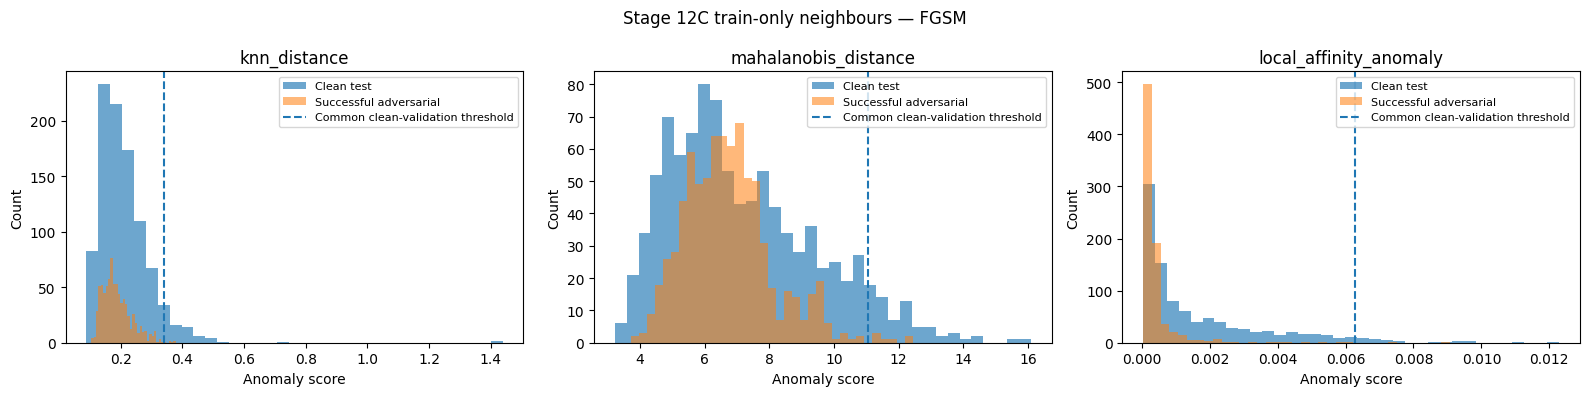

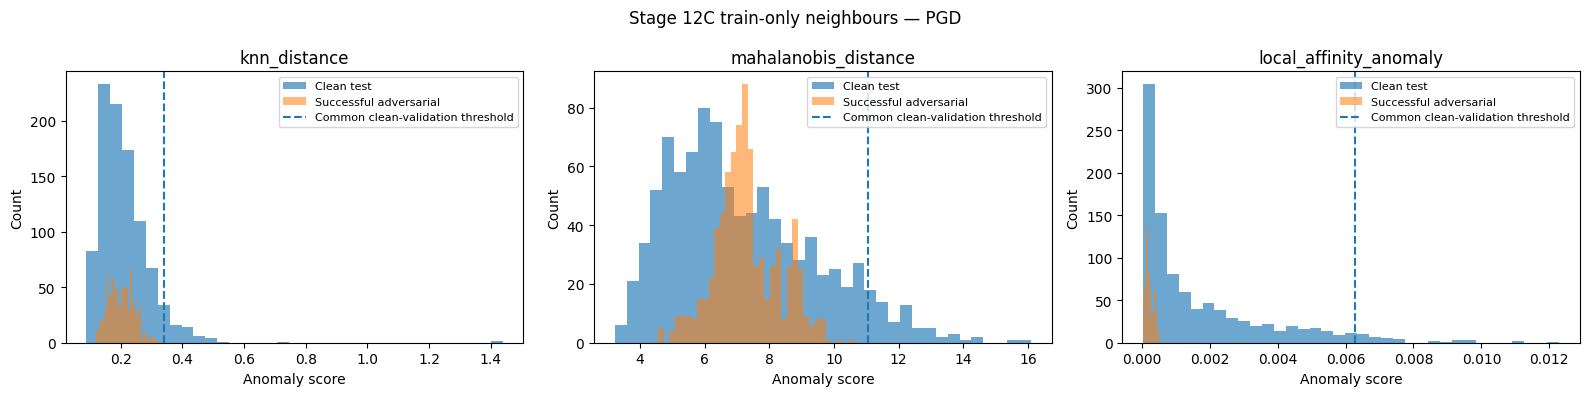

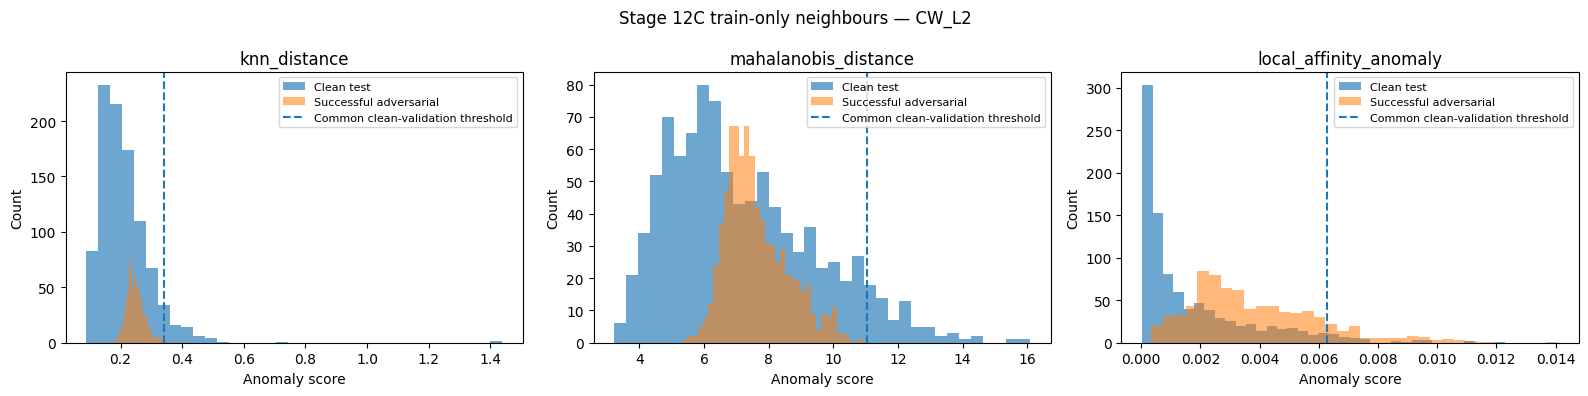

Stage 12C outputs saved: /content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Corrected_Outputs
Output archive: /content/drive/MyDrive/Alzheimer_DGI_Research/Stage12C_Outputs.zip


,attack,method,evaluation,threshold,clean_n,adversarial_n,TN,FP,FN,TP,precision,recall,f1,accuracy,false_positive_rate,roc_auc,average_precision
0,FGSM,knn_distance,full_test_960_clean_vs_793_adversarial,0.340176,960,793,904,56,787,6,0.096774,0.007566,0.014035,0.519110,0.058333,0.430560,0.384873
1,FGSM,mahalanobis_distance,full_test_960_clean_vs_793_adversarial,11.052131,960,793,895,65,786,7,0.097222,0.008827,0.016185,0.514546,0.067708,0.474771,0.399052
2,FGSM,local_affinity_anomaly,full_test_960_clean_vs_793_adversarial,0.006285,960,793,920,40,791,2,0.047619,0.002522,0.004790,0.525956,0.041667,0.239326,0.313793
3,PGD,knn_distance,full_test_960_clean_vs_793_adversarial,0.340176,960,793,904,56,792,1,0.017544,0.001261,0.002353,0.516258,0.058333,0.512324,0.419779
4,PGD,mahalanobis_distance,full_test_960_clean_vs_793_adversarial,11.052131,960,793,895,65,793,0,0.000000,0.000000,0.000000,0.510553,0.067708,0.575056,0.445239
5,PGD,local_affinity_anomaly,full_test_960_clean_vs_793_adversarial,0.006285,960,793,920,40,793,0,0.000000,0.000000,0.000000,0.524815,0.041667,0.177427,0.301800
6,CW_L2,knn_distance,full_test_960_clean_vs_793_adversarial,0.340176,960,793,904,56,790,3,0.050847,0.003783,0.007042,0.517399,0.058333,0.730407,0.554016
7,CW_L2,mahalanobis_distance,full_test_960_clean_vs_793_adversarial,11.052131,960,793,895,65,793,0,0.000000,0.000000,0.000000,0.510553,0.067708,0.617180,0.467906
8,CW_L2,local_affinity_anomaly,full_test_960_clean_vs_793_adversarial,0.006285,960,793,920,40,685,108,0.729730,0.136192,0.229543,0.586423,0.041667,0.806099,0.702334


,attack,method,evaluation,threshold,paired_clean_n,paired_adversarial_n,TN,FP,FN,TP,precision,recall,f1,accuracy,false_positive_rate,roc_auc,average_precision
0,FGSM,knn_distance,paired_793_clean_vs_793_adversarial,0.340176,793,793,752,41,787,6,0.127660,0.007566,0.014286,0.477932,0.051702,0.468690,0.451263
1,FGSM,mahalanobis_distance,paired_793_clean_vs_793_adversarial,11.052131,793,793,752,41,786,7,0.145833,0.008827,0.016647,0.478562,0.051702,0.515189,0.465993
2,FGSM,local_affinity_anomaly,paired_793_clean_vs_793_adversarial,0.006285,793,793,772,21,791,2,0.086957,0.002522,0.004902,0.488020,0.026482,0.274708,0.364459
3,PGD,knn_distance,paired_793_clean_vs_793_adversarial,0.340176,793,793,752,41,792,1,0.023810,0.001261,0.002395,0.474779,0.051702,0.554841,0.491455
4,PGD,mahalanobis_distance,paired_793_clean_vs_793_adversarial,11.052131,793,793,752,41,793,0,0.000000,0.000000,0.000000,0.474149,0.051702,0.619394,0.517764
5,PGD,local_affinity_anomaly,paired_793_clean_vs_793_adversarial,0.006285,793,793,772,21,793,0,0.000000,0.000000,0.000000,0.486759,0.026482,0.206517,0.347232
6,CW_L2,knn_distance,paired_793_clean_vs_793_adversarial,0.340176,793,793,752,41,790,3,0.068182,0.003783,0.007168,0.476040,0.051702,0.769821,0.634827
7,CW_L2,mahalanobis_distance,paired_793_clean_vs_793_adversarial,11.052131,793,793,752,41,793,0,0.000000,0.000000,0.000000,0.474149,0.051702,0.661004,0.542640
8,CW_L2,local_affinity_anomaly,paired_793_clean_vs_793_adversarial,0.006285,793,793,772,21,685,108,0.837209,0.136192,0.234273,0.554855,0.026482,0.854572,0.799185


In [15]:
# Hard validation checks before accepting results.
assert len(metrics_full_df)==9 and len(metrics_paired_df)==9
assert set(metrics_full_df['attack'])==set(ATTACKS)
assert set(metrics_full_df['method'])==set(METHODS)
assert (metrics_full_df['clean_n']==960).all()
assert (metrics_full_df['adversarial_n']==793).all()
assert (metrics_paired_df['paired_clean_n']==793).all()
assert (metrics_paired_df['paired_adversarial_n']==793).all()
assert np.isfinite(metrics_full_df[['precision','recall','f1','roc_auc','false_positive_rate']].to_numpy()).all()
assert np.isfinite(metrics_paired_df[['precision','recall','f1','roc_auc','false_positive_rate']].to_numpy()).all()
assert (audit_df['clean_embedding_max_abs_difference']<1e-5).all()
assert (thresholds_df['calibration_n']==len(idx_val)).all()
assert thresholds_df['observed_validation_fpr'].between(0,0.06).all()
for method in METHODS:
    assert metrics_full_df.loc[metrics_full_df.method==method,'threshold'].nunique()==1
    assert metrics_paired_df.loc[metrics_paired_df.method==method,'threshold'].nunique()==1

for attack in ATTACKS:
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for ax,method in zip(axes,METHODS):
        d=scores_df[(scores_df.attack==attack)&(scores_df.method==method)]
        ax.hist(d.loc[d.sample_type=='clean','anomaly_score'],bins=35,alpha=.65,label='Clean test')
        ax.hist(d.loc[d.sample_type=='successful_adversarial','anomaly_score'],bins=35,alpha=.55,label='Successful adversarial')
        ax.axvline(common_thresholds[method],linestyle='--',label='Common clean-validation threshold')
        ax.set_title(method); ax.set_xlabel('Anomaly score'); ax.set_ylabel('Count'); ax.legend(fontsize=8)
    fig.suptitle(f'Stage 12C train-only neighbours — {attack}')
    fig.tight_layout()
    fig.savefig(OUT/f'stage12C_{attack}_score_distributions.png',dpi=180,bbox_inches='tight')
    plt.show()

metrics_full_df.to_csv(OUT/'stage12C_full_test_metrics.csv',index=False)
metrics_paired_df.to_csv(OUT/'stage12C_paired_test_metrics.csv',index=False)
thresholds_df.to_csv(OUT/'stage12C_common_thresholds.csv',index=False)
scores_df.to_csv(OUT/'stage12C_full_test_sample_scores.csv',index=False)
audit_df.to_csv(OUT/'stage12C_embedding_isolation_audit.csv',index=False)

config={
 'stage':'12C','purpose':'Final train-only neighbour inference with paired and full-test evaluation',
 'seed':SEED,'device':str(DEVICE),'k':K_NEIGHBORS,
 'clean_embeddings':'Original Stage 6 embeddings recomputed on original Stage 5 graph and held fixed',
 'anomaly_reference_bank':'Clean training embeddings only',
 'adversarial_graph_neighbours':'Clean training CNN features only; validation and test nodes excluded',
 'inference_graph':'Directed adversarial-row to clean-training-column edges only; no reverse edges',
 'threshold_calibration':'One common 95th-percentile threshold per score, calibrated from clean validation embeddings only and shared across attacks',
 'evaluations':['960 clean test vs 793 successful adversarial per attack','paired 793 clean originals vs their 793 successful adversarial counterparts'],
 'attack_labels_used_for_fit_or_threshold_selection':False,
 'test_labels_used_for_fit_or_threshold_selection':False,
 'clean_embedding_isolation':'Clean embeddings after adding adversarial nodes must match original clean embeddings within 1e-5',
 'stage6_limitation':'Stage 6 DGI was trained transductively on all 6400 clean nodes; this experiment does not remove Stage 6 transductive exposure.',
 'stage4_stage5_feature_max_abs_difference':max_feature_diff,
 'stage6_embedding_reconstruction_max_abs_difference':max_dgi_diff,
 'successful_test_attack_counts':{a:int(attack_data[('test',a)]['attack_success'].sum()) for a in ATTACKS}
}
with open(OUT/'stage12C_config.json','w') as f: json.dump(config,f,indent=2)
zip_path=ROOT/'Stage12C_Outputs.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as zf:
    for fp in OUT.rglob('*'):
        if fp.is_file(): zf.write(fp,arcname=fp.name)
print('Stage 12C outputs saved:',OUT)
print('Output archive:',zip_path)
display(metrics_full_df); display(metrics_paired_df)


## 10. Interpretation and final-stage stopping criteria

1. Stage 12C is the final planned anomaly-detection experiment. Do not create further stages simply to improve F1.
2. Select conclusions based on protocol validity and consistency, not on the highest metric.
3. The paired analysis uses the exact original clean counterpart for each of the 793 successful adversarial test samples.
4. The full-test analysis retains all 960 clean test images and 793 successful adversarial samples.
5. Thresholds are calibrated only on clean validation embeddings; one threshold per score is shared across attacks.
6. The neighbour search and anomaly reference bank use clean training nodes only.
7. Stage 6 remains transductive because DGI was trained on the full 6,400-node clean graph. State this limitation in the manuscript.
8. After reviewing Stage 12C, freeze the experimental protocol and move to final results comparison, statistical reporting and manuscript revision. Additional experiments should be considered only if a concrete methodological failure is discovered.
